# Ujian Tengah Semester Graf Sains Data

## 1. Tugas Pendahuluan

### 1.2 Mempelajari Penggunaan Driver Neo4j

#### Jawaban Pertanyaan Checkpoint

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan adalah `neo4j`, yaitu database bawaan pada Neo4j yang digunakan untuk menyimpan node dan relationship.

**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam 1 instance!**

Akses database lain dalam satu instance Neo4j dapat dilakukan menggunakan perintah `:use nama_database` pada Neo4j Browser atau parameter `database="nama_database"` pada Python Driver. Perintah `SHOW DATABASES` digunakan untuk menampilkan daftar database yang tersedia, sedangkan `CREATE DATABASE nama_database` digunakan untuk membuat database baru apabila didukung oleh edisi Neo4j yang digunakan.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf yang dibuat merupakan graf berarah (*directed graph*) karena setiap relationship `KNOWS` memiliki arah dari node Arthur menuju node Guinevere, Lancelot, dan Merlin. Graf terdiri dari 4 node berlabel `Person` dan 3 relationship bertipe `KNOWS`.

#### Visualisasi Graf Pertemanan

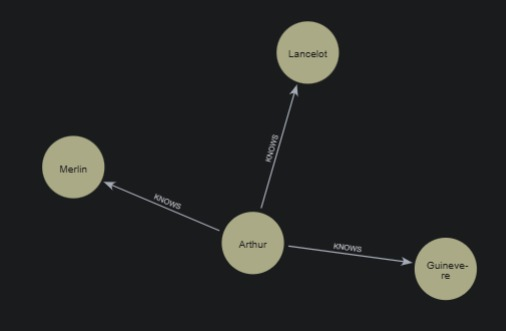

# 1.3 Impor Data RetailRocket ke Database Neo4j

### 1.3.1 Pengunduhan Dataset RetailRocket


In [9]:

!curl -L -o ecommerce-dataset.zip \
"https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  290M  100  290M    0     0  19.4M      0  0:00:14  0:00:14 --:--:-- 22.1M


In [2]:

import os
import zipfile

# Membuat folder data
os.makedirs("data", exist_ok=True)

# Mengekstrak dataset
with zipfile.ZipFile("ecommerce-dataset.zip", "r") as zip_ref:
    zip_ref.extractall("data")

print("Ekstraksi dataset berhasil!")
print("\nDaftar file:")
print(os.listdir("data"))


Ekstraksi dataset berhasil!

Daftar file:
['item_properties_part1.csv', 'item_properties_part2.csv', 'category_tree.csv', 'events.csv']


In [3]:

import pandas as pd

# Membaca dataset RetailRocket
df = pd.read_csv("data/events.csv")

# Menampilkan ukuran dataset
print("Ukuran dataset:", df.shape)

# Menampilkan 5 baris pertama
display(df.head())

# Menampilkan informasi dataset
print("\nInformasi dataset:")
df.info()


Ukuran dataset: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [4]:

# Mengubah timestamp menjadi tanggal
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

print("Tanggal awal:", df["datetime"].min())
print("Tanggal akhir:", df["datetime"].max())

print("\nJumlah data setiap bulan:")
print(df.groupby(df["datetime"].dt.to_period("M")).size())


Tanggal awal: 2015-05-03 03:00:04.384000+00:00
Tanggal akhir: 2015-09-18 02:59:47.788000+00:00

Jumlah data setiap bulan:
datetime
2015-05    590652
2015-06    610393
2015-07    697984
2015-08    553362
2015-09    303710
Freq: M, dtype: int64


/tmp/ipykernel_460/3139674954.py:10: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  print(df.groupby(df["datetime"].dt.to_period("M")).size())


# 2. SOAL UTS

## 2.1 Wrangling dan EDA

### Nomor 1. Penentuan Periode Training dan Testing

Periode P1 (training) ditentukan mulai 6 Mei 2015 sampai sebelum 5 Juni 2015, sedangkan periode P2 (testing) ditentukan mulai 2 September 2015 sampai sebelum 16 September 2015.

Pemilihan periode dilakukan dengan mempertimbangkan ketersediaan data, urutan waktu antara training dan testing, serta ketentuan bahwa kombinasi periode tidak boleh sama dengan mahasiswa lain.

### Nomor 2. Filter Timestamp dan Penyimpanan CSV

In [10]:

import pandas as pd

# Menentukan periode P1 dan P2
p1_start = pd.Timestamp("2015-05-06", tz="UTC")
p1_end = pd.Timestamp("2015-06-05", tz="UTC")

p2_start = pd.Timestamp("2015-09-02", tz="UTC")
p2_end = pd.Timestamp("2015-09-16", tz="UTC")

# Filter periode training (P1)
df_p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < p1_end)
].copy()

# Filter periode testing (P2)
df_p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < p2_end)
].copy()

print("Jumlah data awal:", len(df))
print("Jumlah data P1 (Training):", len(df_p1))
print("Jumlah data P2 (Testing):", len(df_p2))

print("\nRentang tanggal P1:")
print(df_p1["datetime"].min())
print(df_p1["datetime"].max())

print("\nRentang tanggal P2:")
print(df_p2["datetime"].min())
print(df_p2["datetime"].max())


Jumlah data awal: 2756101
Jumlah data P1 (Training): 627860
Jumlah data P2 (Testing): 262381

Rentang tanggal P1:
2015-05-06 00:00:01.925000+00:00
2015-06-04 23:59:56.235000+00:00

Rentang tanggal P2:
2015-09-02 00:00:10.579000+00:00
2015-09-15 23:59:58.763000+00:00


In [11]:

import os

os.makedirs("hasil_filter", exist_ok=True)

# Memilih kolom asli dataset
kolom = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

# Menyimpan data training dan testing
df_p1[kolom].to_csv(
    "hasil_filter/P1_training.csv",
    index=False
)

df_p2[kolom].to_csv(
    "hasil_filter/P2_testing.csv",
    index=False
)

print("File CSV berhasil disimpan!")
print("P1_training.csv:", len(df_p1), "baris")
print("P2_testing.csv:", len(df_p2), "baris")


File CSV berhasil disimpan!
P1_training.csv: 627860 baris
P2_testing.csv: 262381 baris


In [8]:

# Memeriksa pengunjung dan item yang sama
user_p1 = set(df_p1["visitorid"])
user_p2 = set(df_p2["visitorid"])

item_p1 = set(df_p1["itemid"])
item_p2 = set(df_p2["itemid"])

print("Pengunjung unik P1:", len(user_p1))
print("Pengunjung unik P2:", len(user_p2))
print("Pengunjung yang muncul di kedua periode:",
      len(user_p1 & user_p2))

print("\nItem unik P1:", len(item_p1))
print("Item unik P2:", len(item_p2))
print("Item yang muncul di kedua periode:",
      len(item_p1 & item_p2))

print("\nDistribusi event P1:")
display(df_p1["event"].value_counts())

print("\nDistribusi event P2:")
display(df_p2["event"].value_counts())


Pengunjung unik P1: 325964
Pengunjung unik P2: 151296
Pengunjung yang muncul di kedua periode: 3059

Item unik P1: 118508
Item unik P2: 75437
Item yang muncul di kedua periode: 45574

Distribusi event P1:


,count
event,
view,607737
addtocart,15159
transaction,4964



Distribusi event P2:


,count
event,
view,253753
addtocart,6614
transaction,2014


### Pembahasan Nomor 1 dan 2

Hasil filter timestamp pada dataset RetailRocket menghasilkan 627.860 interaksi untuk periode P1 (training) dan 262.381 interaksi untuk periode P2 (testing). Periode P1 memiliki 325.964 pengunjung unik dan 118.508 item unik, sedangkan periode P2 memiliki 151.296 pengunjung unik dan 75.437 item unik.

Jenis interaksi yang paling dominan pada kedua periode adalah *view*, diikuti *addtocart* dan *transaction*. Pemisahan periode dilakukan secara kronologis untuk memastikan data testing berasal dari waktu setelah data training.



### Nomor 3. Query Komposisi Subgraph

Pada tahap ini dilakukan analisis komposisi subgraph periode P1 (training) yang telah diimpor ke database Neo4j. Analisis bertujuan untuk mengidentifikasi jenis simpul, jumlah masing-masing simpul, serta jumlah relationship berdasarkan jenis interaksi menggunakan Python API Neo4j dan query Cypher.

In [ ]:

import os
import getpass
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"

password = os.getenv("NEO4J_PASSWORD") or getpass.getpass(
    "Password Neo4j: "
)

driver = GraphDatabase.driver(
    uri,
    auth=(user, password)
)

try:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:

        print("=== JUMLAH SIMPUL ===")

        result = session.run("""
            MATCH (n)
            RETURN labels(n) AS jenis_simpul,
                   count(n) AS jumlah
        """)

        for record in result:
            print(record["jenis_simpul"], record["jumlah"])

        print("\n=== JUMLAH RELATIONSHIP ===")

        result = session.run("""
            MATCH ()-[r]->()
            RETURN type(r) AS jenis,
                   count(r) AS jumlah
        """)

        for record in result:
            print(record["jenis"], record["jumlah"])

finally:
    driver.close()



**Hasil Eksekusi Python API Neo4j (VS Code)**

```text
=== JUMLAH SIMPUL ===
['Visitor'] 325964
['Item'] 118508

=== JUMLAH RELATIONSHIP ===
VIEWED 607737
ADDED_TO_CART 15159
BOUGHT 4964
```

**Penjelasan Query Cypher**



### Penjelasan Query Cypher

Query `MATCH (n)` digunakan untuk mengambil seluruh simpul dalam database Neo4j. Fungsi `labels(n)` digunakan untuk mengetahui label simpul, sedangkan `count(n)` digunakan untuk menghitung jumlah simpul berdasarkan labelnya.

Query `MATCH ()-[r]->()` digunakan untuk mengambil seluruh relationship pada graf. Fungsi `type(r)` digunakan untuk mengidentifikasi jenis relationship, sedangkan `count(r)` digunakan untuk menghitung jumlah relationship berdasarkan jenisnya.

### Interpretasi Hasil Nomor 3

Hasil analisis menunjukkan bahwa subgraph P1 terdiri dari 444.472 simpul, yaitu 325.964 simpul Visitor dan 118.508 simpul Item.

Jumlah relationship sebanyak 627.860, terdiri dari 607.737 VIEWED, 15.159 ADDED_TO_CART, dan 4.964 BOUGHT.

Graf yang terbentuk merupakan graf bipartit berarah karena relationship menghubungkan simpul Visitor menuju simpul Item. Interaksi VIEWED mendominasi sehingga aktivitas melihat produk merupakan aktivitas yang paling banyak tercatat pada periode P1.


### Nomor 4. Vector Space Modelling (VSM) User

In [12]:

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Menggunakan dataset P1 (training)
data = df_p1.copy()

# Mengubah ID user dan item menjadi indeks
user_codes, user_ids = pd.factorize(data["visitorid"])
item_codes, item_ids = pd.factorize(data["itemid"])

# Membuat matriks User-Item
matrix_user = csr_matrix(
    (
        np.ones(len(data), dtype=np.float32),
        (user_codes, item_codes)
    ),
    shape=(len(user_ids), len(item_ids))
)

# Mengubah nilai interaksi menjadi biner
matrix_user.data[:] = 1

# Menampilkan karakteristik matriks
print("=== VSM USER ===")
print("Jumlah User:", matrix_user.shape[0])
print("Jumlah Item:", matrix_user.shape[1])
print("Dimensi matriks:", matrix_user.shape)
print("Jumlah pasangan User-Item unik:", matrix_user.nnz)
print("Jumlah elemen bukan nol:", matrix_user.nnz)


=== VSM USER ===
Jumlah User: 325964
Jumlah Item: 118508
Dimensi matriks: (325964, 118508)
Jumlah pasangan User-Item unik: 487584
Jumlah elemen bukan nol: 487584


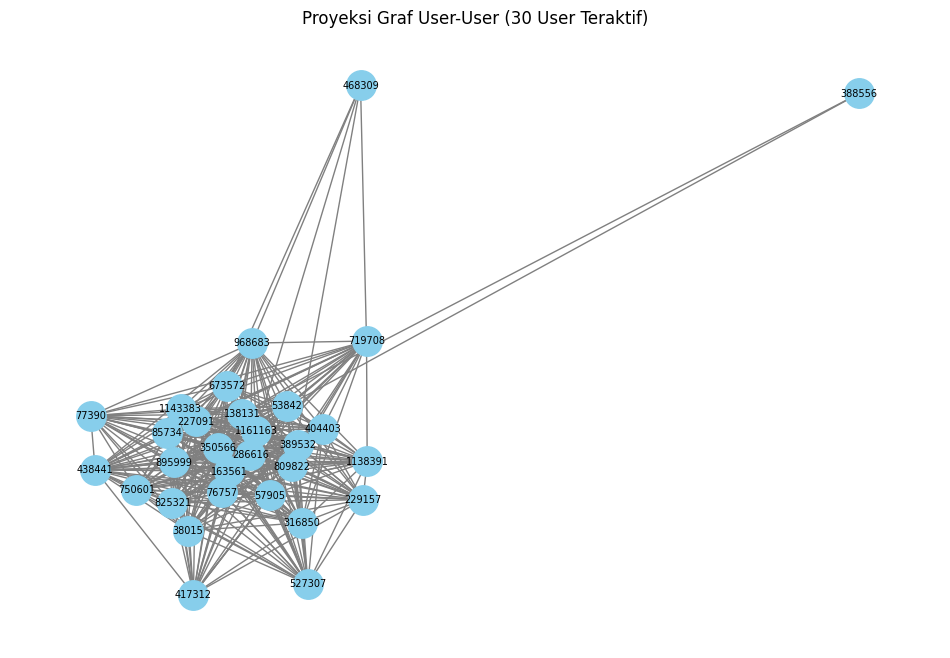

Jumlah node: 30
Jumlah edge: 371


In [13]:

import networkx as nx
import matplotlib.pyplot as plt

# Memilih 30 user yang paling aktif
top_users = (
    data["visitorid"]
    .value_counts()
    .head(30)
    .index
)

# Mengambil interaksi dari 30 user
sample_data = data[
    data["visitorid"].isin(top_users)
]

# Membuat himpunan item untuk setiap user
user_items = (
    sample_data.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# Membuat graf proyeksi User-User
G_user = nx.Graph()

for user in top_users:
    G_user.add_node(int(user))

users = list(user_items.keys())

for i in range(len(users)):
    for j in range(i + 1, len(users)):

        common_items = (
            user_items[users[i]] &
            user_items[users[j]]
        )

        if len(common_items) > 0:
            G_user.add_edge(
                int(users[i]),
                int(users[j]),
                weight=len(common_items)
            )

# Visualisasi graf
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    node_color="skyblue",
    node_size=450,
    edge_color="gray",
    font_size=7,
    with_labels=True
)

plt.title("Proyeksi Graf User-User (30 User Teraktif)")
plt.axis("off")
plt.show()

print("Jumlah node:", G_user.number_of_nodes())
print("Jumlah edge:", G_user.number_of_edges())



### Pembahasan Nomor 4

Vector Space Modelling (VSM) berbasis User dilakukan dengan merepresentasikan setiap pengunjung sebagai vektor berdasarkan item yang pernah diinteraksikan pada periode P1 (training), yaitu 6 Mei 2015 sampai sebelum 5 Juni 2015.

Matriks User-Item memiliki dimensi 325.964 × 118.508, dengan baris mewakili User dan kolom mewakili Item. Matriks menggunakan representasi biner, yaitu nilai 1 apabila terdapat interaksi dan 0 apabila tidak terdapat interaksi yang tercatat. Penggunaan sparse matrix bertujuan menghemat memori karena sebagian besar kombinasi User dan Item tidak memiliki interaksi.

Proyeksi graf User-User menggunakan NetworkX dengan sampel 30 User teraktif menghasilkan 30 node dan 371 edge. Setiap edge menunjukkan adanya minimal satu Item yang sama-sama diinteraksikan oleh dua User, sedangkan bobot edge menunjukkan jumlah Item yang sama.

Graf menunjukkan hubungan antarpengguna yang relatif padat, dengan sebagian besar User saling terhubung melalui kesamaan interaksi terhadap Item. Hasil ini menunjukkan adanya pola interaksi bersama yang dapat digunakan sebagai dasar analisis similarity antarpengguna.


### Nomor 5. Vector Space Modelling (VSM) Item

In [14]:

import numpy as np
from scipy.sparse import csr_matrix

# Menggunakan matriks User-Item dari Nomor 4
# Transpose untuk mendapatkan matriks Item-User
matrix_item = matrix_user.T.tocsr()

print("=== VSM ITEM ===")
print("Jumlah Item:", matrix_item.shape[0])
print("Jumlah User:", matrix_item.shape[1])
print("Dimensi matriks:", matrix_item.shape)
print("Jumlah pasangan Item-User unik:", matrix_item.nnz)

# Menghitung kepadatan matriks
total_elemen = matrix_item.shape[0] * matrix_item.shape[1]
density = matrix_item.nnz / total_elemen * 100

print("Kepadatan matriks: {:.6f}%".format(density))


=== VSM ITEM ===
Jumlah Item: 118508
Jumlah User: 325964
Dimensi matriks: (118508, 325964)
Jumlah pasangan Item-User unik: 487584
Kepadatan matriks: 0.001262%


In [41]:

# NOMOR 5 - MEMBENTUK GRAF ITEM-ITEM

import networkx as nx

# Memilih 30 Item paling aktif
top_items = (
    df_p1["itemid"]
    .value_counts()
    .head(30)
    .index
)

# Mengambil interaksi untuk Item terpilih
sample_item = df_p1[
    df_p1["itemid"].isin(top_items)
][["visitorid", "itemid"]].drop_duplicates()

# Membentuk himpunan User untuk setiap Item
item_users = (
    sample_item.groupby("itemid")["visitorid"]
    .apply(set)
    .to_dict()
)

G_item = nx.Graph()
G_item.add_nodes_from(int(item) for item in top_items)

items = list(item_users.keys())

for i in range(len(items)):
    for j in range(i + 1, len(items)):
        common_users = item_users[items[i]] & item_users[items[j]]

        if common_users:
            G_item.add_edge(
                int(items[i]),
                int(items[j]),
                weight=len(common_users)
            )

print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())


Jumlah node: 30
Jumlah edge: 204


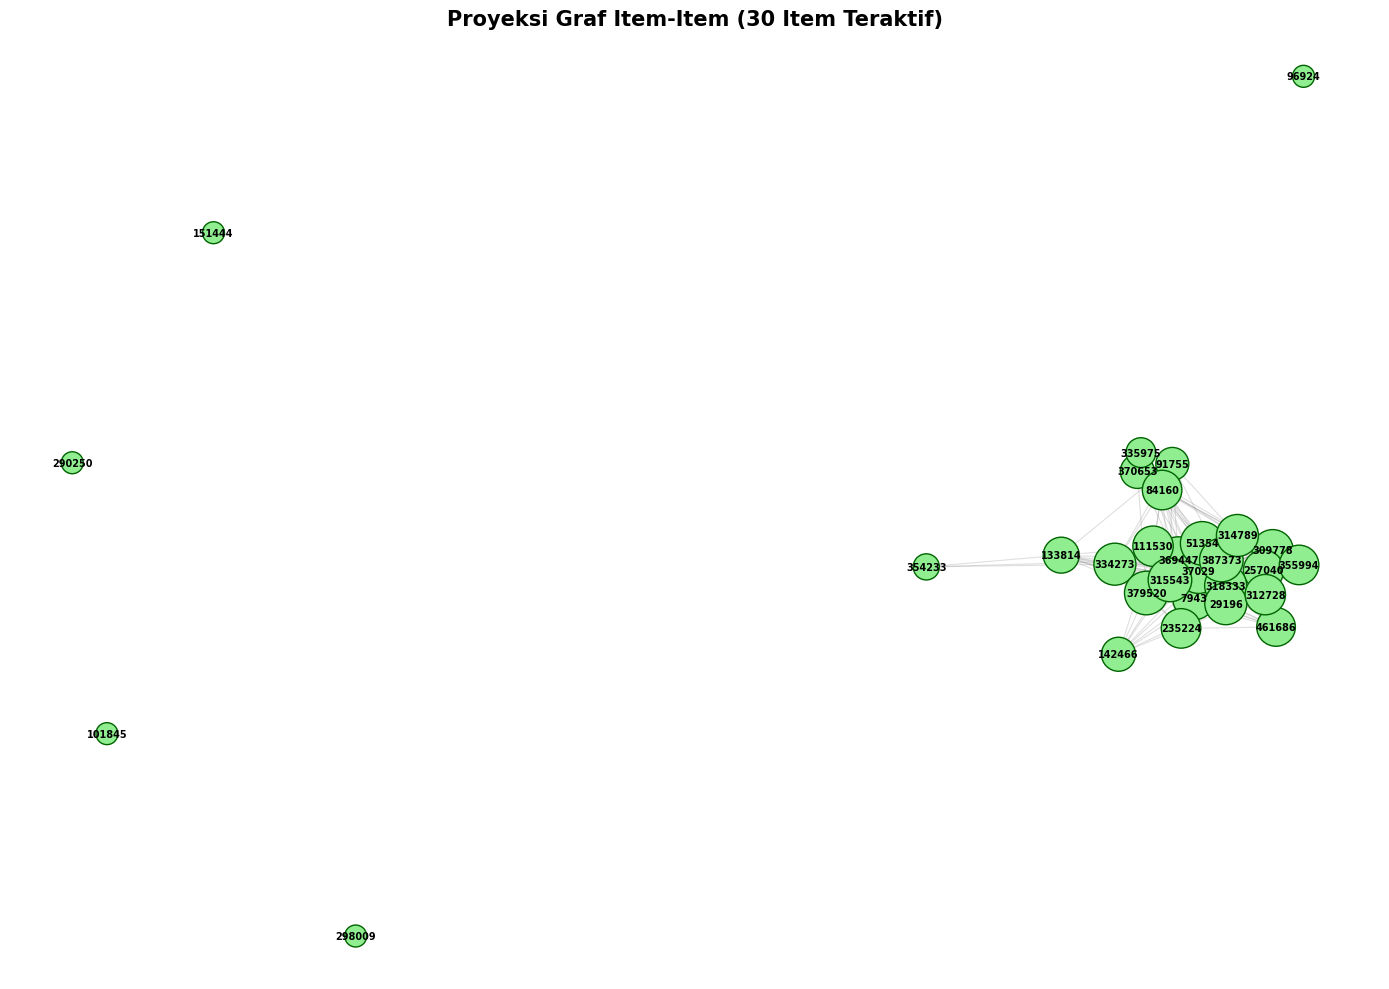

Jumlah node: 30
Jumlah edge: 204


In [18]:

import networkx as nx
import matplotlib.pyplot as plt

# Menggunakan graf Item-Item yang sudah dibuat
plt.figure(figsize=(14, 10))

# Mengatur posisi node agar lebih menyebar
pos = nx.spring_layout(
    G_item,
    seed=42,
    k=1.5,
    iterations=200
)

# Mengatur ukuran node berdasarkan degree
node_sizes = [
    250 + G_item.degree(node) * 35
    for node in G_item.nodes()
]

# Menggambar edge
nx.draw_networkx_edges(
    G_item,
    pos,
    edge_color="gray",
    alpha=0.25,
    width=0.8
)

# Menggambar node
nx.draw_networkx_nodes(
    G_item,
    pos,
    node_color="lightgreen",
    node_size=node_sizes,
    edgecolors="darkgreen",
    linewidths=1
)

# Menggambar label
nx.draw_networkx_labels(
    G_item,
    pos,
    font_size=7,
    font_weight="bold"
)

plt.title(
    "Proyeksi Graf Item-Item (30 Item Teraktif)",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())



### Pembahasan Nomor 5

Vector Space Modelling (VSM) berbasis Item dilakukan dengan merepresentasikan setiap produk sebagai vektor berdasarkan pengunjung yang pernah berinteraksi dengan produk tersebut pada periode P1 (training), yaitu 6 Mei 2015 sampai sebelum 5 Juni 2015.

Matriks Item-User merupakan hasil transpose dari matriks User-Item sehingga memiliki dimensi 118.508 × 325.964. Setiap baris mewakili Item dan setiap kolom mewakili User. Nilai matriks bersifat biner, yaitu 1 apabila terdapat interaksi dan 0 apabila tidak terdapat interaksi yang tercatat.

Proyeksi graf Item-Item menggunakan NetworkX dengan sampel 30 Item teraktif menghasilkan 30 node dan 204 edge. Dua Item dihubungkan apabila pernah diinteraksikan oleh minimal satu User yang sama.

Visualisasi menunjukkan adanya kelompok Item yang memiliki hubungan cukup padat, sedangkan beberapa Item tidak memiliki hubungan dengan Item lain dalam sampel. Hal ini menunjukkan adanya perbedaan pola interaksi pengunjung terhadap produk.


### Nomor 6. Perbandingan Efektivitas dan Efisiensi Proyeksi Graf

In [19]:

import networkx as nx
import pandas as pd

# Menghitung karakteristik graf User-User
# dan Item-Item dari hasil Nomor 4 dan 5

hasil = {
    "Karakteristik": [
        "Jumlah Node",
        "Jumlah Edge",
        "Density",
        "Average Degree",
        "Jumlah Komponen",
        "Node Terisolasi"
    ],
    "User-User": [
        G_user.number_of_nodes(),
        G_user.number_of_edges(),
        nx.density(G_user),
        sum(dict(G_user.degree()).values()) / G_user.number_of_nodes(),
        nx.number_connected_components(G_user),
        nx.number_of_isolates(G_user)
    ],
    "Item-Item": [
        G_item.number_of_nodes(),
        G_item.number_of_edges(),
        nx.density(G_item),
        sum(dict(G_item.degree()).values()) / G_item.number_of_nodes(),
        nx.number_connected_components(G_item),
        nx.number_of_isolates(G_item)
    ]
}

df_perbandingan = pd.DataFrame(hasil)

display(df_perbandingan)


,Karakteristik,User-User,Item-Item
0,Jumlah Node,30.000000,30.000000
1,Jumlah Edge,371.000000,204.000000
2,Density,0.852874,0.468966
3,Average Degree,24.733333,13.600000
4,Jumlah Komponen,1.000000,6.000000
5,Node Terisolasi,0.000000,5.000000


In [20]:

# Merapikan tampilan tabel perbandingan
df_rapi = df_perbandingan.copy()

for kolom in ["User-User", "Item-Item"]:
    df_rapi[kolom] = [
        f"{int(nilai)}" if karakteristik in [
            "Jumlah Node",
            "Jumlah Edge",
            "Jumlah Komponen",
            "Node Terisolasi"
        ] else f"{nilai:.4f}"
        for karakteristik, nilai in zip(
            df_rapi["Karakteristik"],
            df_rapi[kolom]
        )
    ]

display(df_rapi)


,Karakteristik,User-User,Item-Item
0,Jumlah Node,30,30
1,Jumlah Edge,371,204
2,Density,0.8529,0.4690
3,Average Degree,24.7333,13.6000
4,Jumlah Komponen,1,6
5,Node Terisolasi,0,5



### Pembahasan Nomor 6

Perbandingan proyeksi graf dilakukan terhadap hasil VSM berbasis User dan Item pada dataset P1 (training). Kedua proyeksi menggunakan sampel sebanyak 30 simpul teraktif untuk mempermudah visualisasi dan analisis.

Proyeksi User-User menghasilkan 30 node dan 371 edge dengan density sebesar 0,8529 serta average degree sebesar 24,73. Sementara itu, proyeksi Item-Item menghasilkan 30 node dan 204 edge dengan density sebesar 0,4690 serta average degree sebesar 13,60.

Dari segi konektivitas pada sampel, proyeksi User-User lebih efektif dalam memperlihatkan hubungan kesamaan interaksi karena memiliki jumlah edge dan density lebih tinggi. Sebaliknya, proyeksi Item-Item lebih efisien dari segi jumlah edge yang perlu disimpan dan dianalisis karena memiliki hubungan yang lebih sedikit.

Namun, kepadatan graf tidak secara langsung menunjukkan kualitas rekomendasi maupun waktu komputasi yang lebih baik. Penilaian tersebut memerlukan pengujian similarity dan evaluasi rekomendasi lebih lanjut. Oleh karena itu, kedua proyeksi memiliki keunggulan masing-masing sesuai tujuan analisis.


### Nomor 7. Perhitungan Similarity pada Proyeksi User-User

In [21]:

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Mengambil 30 User yang sama dengan Nomor 4
user_terpilih = list(top_users)

# Mengambil indeks User dari matriks VSM Nomor 4
indeks_user = pd.Index(user_ids).get_indexer(user_terpilih)

# Memastikan seluruh User ditemukan
assert (indeks_user >= 0).all(), "Ada User yang tidak ditemukan"

# Mengambil vektor interaksi 30 User dari P1
vsm_user_sampel = matrix_user[indeks_user, :]

# Menghitung Cosine Similarity
similarity_user = cosine_similarity(vsm_user_sampel)

# Membuat DataFrame similarity
df_similarity = pd.DataFrame(
    similarity_user,
    index=user_terpilih,
    columns=user_terpilih
)

print("=== COSINE SIMILARITY USER-USER ===")
print("Dimensi matriks:", df_similarity.shape)

display(df_similarity.round(4))


=== COSINE SIMILARITY USER-USER ===
Dimensi matriks: (30, 30)


,286616,163561,350566,76757,389532,809822,1161163,138131,57905,53842,...,229157,895999,750601,673572,468309,388556,438441,417312,825321,968683
286616,1.0000,0.1463,0.1323,0.0779,0.1316,0.0937,0.1022,0.1132,0.1195,0.0704,...,0.0299,0.0625,0.0630,0.0788,0.0000,0.0000,0.0564,0.0145,0.0668,0.0311
163561,0.1463,1.0000,0.1298,0.0895,0.0879,0.0783,0.0979,0.1004,0.1206,0.0674,...,0.0298,0.0926,0.0588,0.0858,0.0000,0.0000,0.0680,0.0491,0.0729,0.0289
350566,0.1323,0.1298,1.0000,0.0951,0.0977,0.0744,0.0968,0.0973,0.1025,0.0878,...,0.0380,0.0771,0.0537,0.0688,0.0000,0.0000,0.0536,0.0104,0.0651,0.0274
76757,0.0779,0.0895,0.0951,1.0000,0.0625,0.0757,0.0878,0.0685,0.0507,0.0627,...,0.0209,0.0795,0.0544,0.0665,0.0000,0.0000,0.0244,0.0086,0.0620,0.0308
389532,0.1316,0.0879,0.0977,0.0625,1.0000,0.0778,0.0780,0.0960,0.0630,0.0623,...,0.0375,0.0599,0.0341,0.0738,0.0000,0.0000,0.0251,0.0221,0.0573,0.0158
809822,0.0937,0.0783,0.0744,0.0757,0.0778,1.0000,0.0896,0.0758,0.0816,0.0938,...,0.0272,0.0609,0.0536,0.0583,0.0085,0.0000,0.0291,0.0269,0.0453,0.0225
1161163,0.1022,0.0979,0.0968,0.0878,0.0780,0.0896,1.0000,0.0697,0.0990,0.0702,...,0.0239,0.0621,0.0553,0.0731,0.0041,0.0000,0.0426,0.0044,0.0537,0.0313
138131,0.1132,0.1004,0.0973,0.0685,0.0960,0.0758,0.0697,1.0000,0.0761,0.0553,...,0.0249,0.0477,0.0671,0.0563,0.0000,0.0117,0.0148,0.0182,0.0624,0.0293
57905,0.1195,0.1206,0.1025,0.0507,0.0630,0.0816,0.0990,0.0761,1.0000,0.0450,...,0.0169,0.0600,0.0618,0.0459,0.0000,0.0000,0.0263,0.0371,0.0334,0.0199
53842,0.0704,0.0674,0.0878,0.0627,0.0623,0.0938,0.0702,0.0553,0.0450,1.0000,...,0.0250,0.0452,0.0257,0.0709,0.0000,0.0118,0.0223,0.0138,0.0430,0.0131


In [22]:

# Mengambil pasangan User tanpa duplikasi
hasil_pasangan = []

for i in range(len(user_terpilih)):
    for j in range(i + 1, len(user_terpilih)):

        hasil_pasangan.append({
            "User 1": int(user_terpilih[i]),
            "User 2": int(user_terpilih[j]),
            "Cosine Similarity": float(
                similarity_user[i, j]
            )
        })

df_pasangan = pd.DataFrame(hasil_pasangan)

# Mengurutkan berdasarkan similarity tertinggi
df_top10 = (
    df_pasangan
    .sort_values(
        "Cosine Similarity",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

print("=== 10 PASANGAN USER PALING MIRIP ===")
display(df_top10.round(4))


=== 10 PASANGAN USER PALING MIRIP ===


,User 1,User 2,Cosine Similarity
0,286616,163561,0.1463
1,85734,673572,0.1339
2,286616,350566,0.1323
3,286616,389532,0.1316
4,163561,350566,0.1298
5,163561,57905,0.1206
6,286616,57905,0.1195
7,316850,527307,0.1189
8,85734,895999,0.1160
9,286616,138131,0.1132


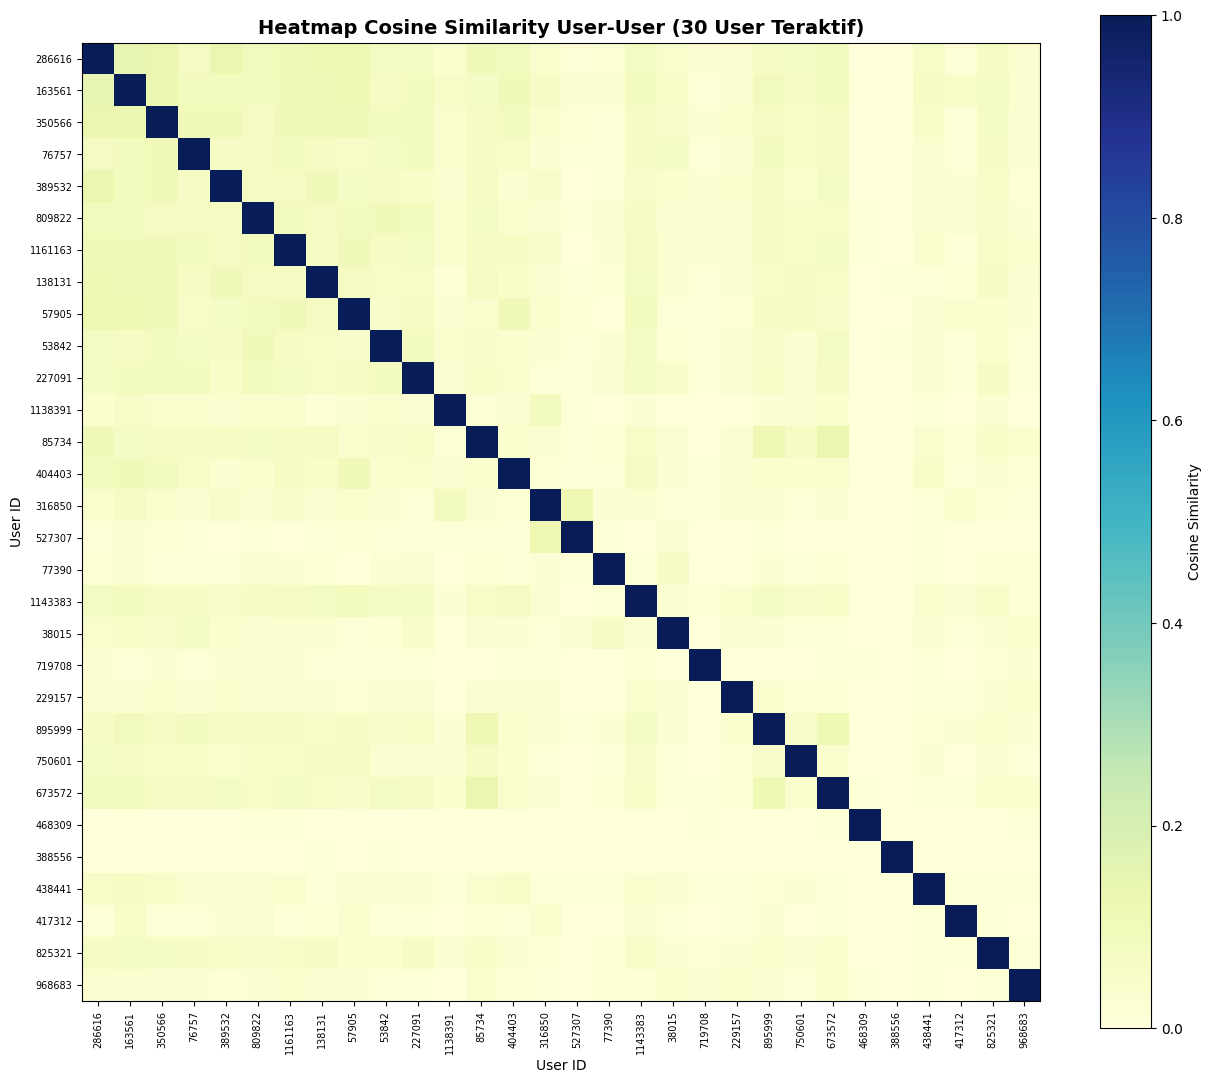

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 11))

plt.imshow(
    similarity_user,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Cosine Similarity")

plt.xticks(
    range(len(user_terpilih)),
    user_terpilih,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(user_terpilih)),
    user_terpilih,
    fontsize=7
)

plt.title(
    "Heatmap Cosine Similarity User-User (30 User Teraktif)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("User ID")
plt.ylabel("User ID")

plt.tight_layout()
plt.show()


In [24]:

# Mengambil nilai similarity selain diagonal
nilai_similarity = similarity_user[
    np.triu_indices_from(similarity_user, k=1)
]

print("=== STATISTIK COSINE SIMILARITY ===")
print("Jumlah pasangan User:", len(nilai_similarity))
print("Similarity minimum:", round(nilai_similarity.min(), 4))
print("Similarity maksimum:", round(nilai_similarity.max(), 4))
print("Similarity rata-rata:", round(nilai_similarity.mean(), 4))
print("Jumlah pasangan dengan similarity > 0:",
      np.sum(nilai_similarity > 0))


=== STATISTIK COSINE SIMILARITY ===
Jumlah pasangan User: 435
Similarity minimum: 0.0
Similarity maksimum: 0.1463
Similarity rata-rata: 0.0355
Jumlah pasangan dengan similarity > 0: 371


In [58]:

# Menyiapkan hasil similarity untuk Neo4j
df_similarity_export = df_pasangan.copy()

df_similarity_export = df_similarity_export.rename(
    columns={
        "User 1": "user1",
        "User 2": "user2",
        "Cosine Similarity": "similarity"
    }
)

# Hanya menyimpan pasangan dengan similarity positif
df_similarity_export = df_similarity_export[
    df_similarity_export["similarity"] > 0
].copy()

# Menyimpan ke CSV
df_similarity_export.to_csv(
    "similarity_user.csv",
    index=False
)

print("File similarity_user.csv berhasil dibuat!")
print("Jumlah pasangan:", len(df_similarity_export))
display(df_similarity_export.head())


File similarity_user.csv berhasil dibuat!
Jumlah pasangan: 371


,user1,user2,similarity
0,286616,163561,0.146277
1,286616,350566,0.132288
2,286616,76757,0.077892
3,286616,389532,0.131590
4,286616,809822,0.093715



### Nomor 7(a). Query Cypher untuk 5 Similarity Tertinggi

Perhitungan Cosine Similarity dilakukan menggunakan matriks User–Item dari 30 User teraktif pada periode P1. User 286616 dipilih sebagai User acuan.

Hasil similarity disimpan dalam relationship SIMILAR_TO pada database Neo4j. Query berikut digunakan untuk mengambil lima User dengan nilai similarity tertinggi.

**Query Cypher:**

```cypher
MATCH (u1:Visitor {visitorid: 286616})-[r:SIMILAR_TO]-(u2:Visitor)
RETURN
    u1.visitorid AS User_Acuan,
    u2.visitorid AS User_Mirip,
    round(r.similarity, 4) AS Cosine_Similarity
ORDER BY r.similarity DESC
LIMIT 5;
```
**Hasil Eksekusi Query Neo4j:**

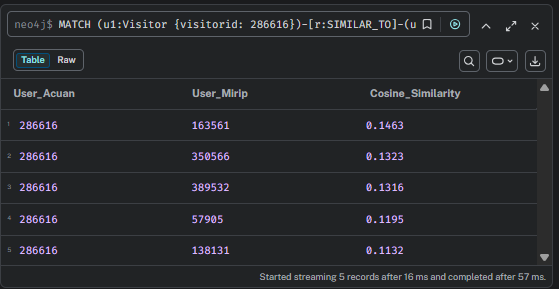

**Hasil Query Neo4j:**

| User Acuan | User Mirip | Cosine Similarity |
|---|---|---|
| 286616 | 163561 | 0,1463 |
| 286616 | 350566 | 0,1323 |
| 286616 | 389532 | 0,1316 |
| 286616 | 57905 | 0,1195 |
| 286616 | 138131 | 0,1132 |

**Interpretasi:**

User 163561 memiliki kemiripan tertinggi dengan User 286616, yaitu sebesar 0,1463. Semakin tinggi nilai Cosine Similarity, semakin mirip pola interaksi item kedua User.



### Nomor 7(b). Visualisasi Nilai Similarity pada Graf

Pada tahap ini, nilai Cosine Similarity yang telah dihitung ditampilkan kembali pada graf Neo4j menggunakan relationship SIMILAR_TO. User 286616 digunakan sebagai node acuan yang dihubungkan dengan lima User yang memiliki similarity tertinggi.

**Kode Query Cypher:**

```cypher
MATCH (u1:Visitor {visitorid: 286616})-[r:SIMILAR_TO]-(u2:Visitor)
WITH u1, u2, r
ORDER BY r.similarity DESC
LIMIT 5
RETURN u1, r, u2;
```

**Hasil Visualisasi Graf Neo4j:**

*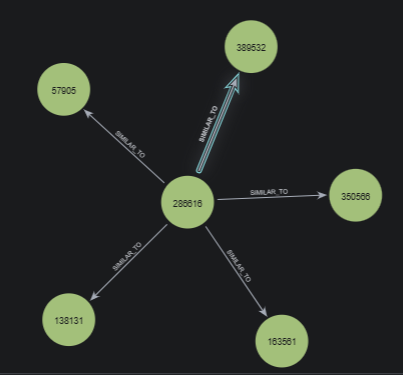

**Interpretasi:**

Graf menunjukkan satu node acuan, yaitu User 286616, yang terhubung dengan lima User lainnya melalui relationship SIMILAR_TO. Hubungan dengan similarity tertinggi terdapat pada User 163561 sebesar 0,1463, sedangkan nilai terendah di antara lima User terpilih terdapat pada User 138131 sebesar 0,1132.

Visualisasi ini memperlihatkan kesamaan pola interaksi antar-User yang dihitung menggunakan Cosine Similarity. Semakin tinggi nilai similarity, semakin besar tingkat kesamaan pola interaksi kedua User pada data yang dianalisis.


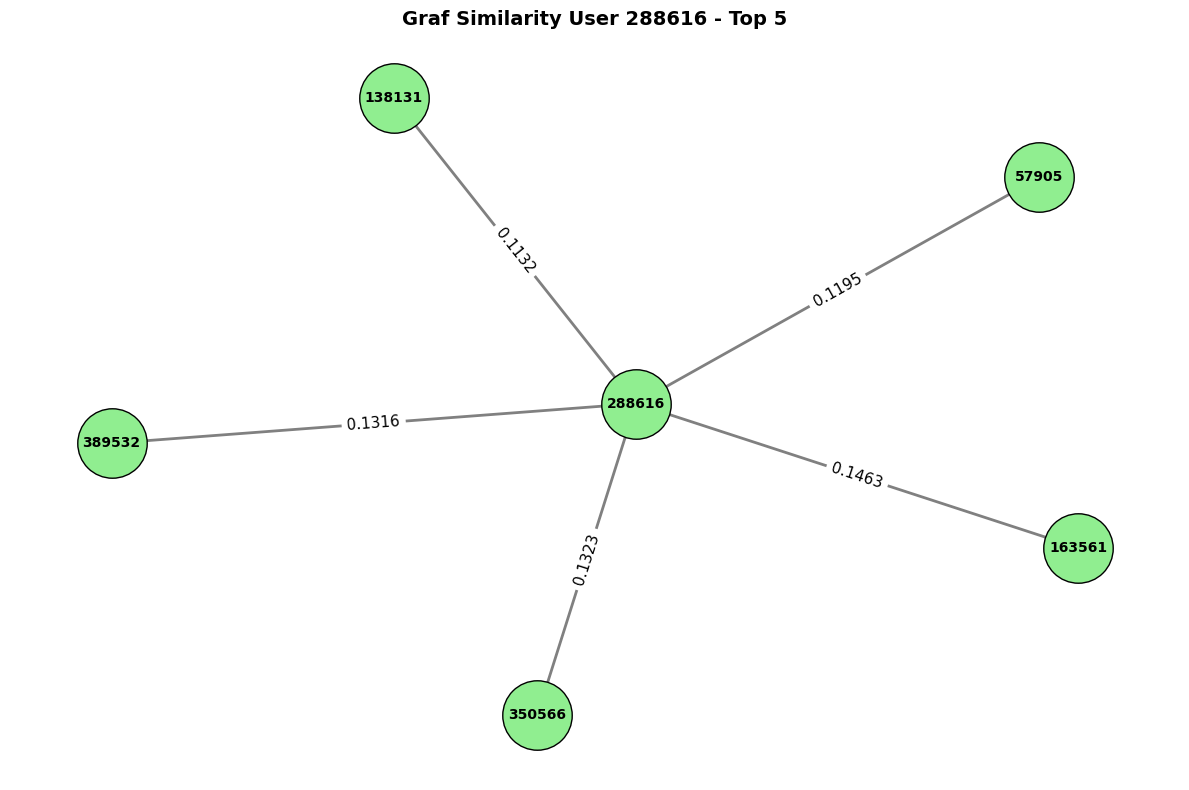

In [27]:

import networkx as nx
import matplotlib.pyplot as plt

# Data 5 similarity tertinggi hasil Neo4j
user_acuan = 286616

data_similarity = [
    (286616, 163561, 0.1463),
    (286616, 350566, 0.1323),
    (286616, 389532, 0.1316),
    (286616, 57905, 0.1195),
    (286616, 138131, 0.1132)
]

# Membuat graf
G = nx.Graph()

for user1, user2, similarity in data_similarity:
    G.add_edge(user1, user2, weight=similarity)

# Mengatur posisi node
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G, pos,
    node_color="lightgreen",
    node_size=2500,
    edgecolors="black"
)

nx.draw_networkx_edges(
    G, pos,
    width=2,
    edge_color="gray"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_weight="bold"
)

# Menampilkan angka similarity pada garis
edge_labels = {
    (u, v): f"{d['weight']:.4f}"
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=11,
    bbox=dict(facecolor="white", edgecolor="none")
)

plt.title(
    "Graf Similarity User 286616 - Top 5",
    fontsize=14,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()



## Nomor 8. Perbandingan Graf Sebelum dan Sesudah Perhitungan Similarity

Perbandingan graf dilakukan untuk memperlihatkan kondisi hubungan antar-node sebelum dan sesudah penambahan hasil perhitungan Cosine Similarity. Visualisasi menggunakan query Cypher pada Neo4j dengan User 286616 sebagai node acuan. Subgraph yang sama digunakan agar perubahan hubungan dapat diamati dengan jelas.

### A. Graf Sebelum Perhitungan Similarity

**Query Cypher:**

```cypher

MATCH (u:Visitor {visitorid: 286616})
OPTIONAL MATCH (u)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
WITH u, r, i
LIMIT 15
RETURN u, r, i;
```

**Hasil Visualisasi Graf Sebelum Similarity:**

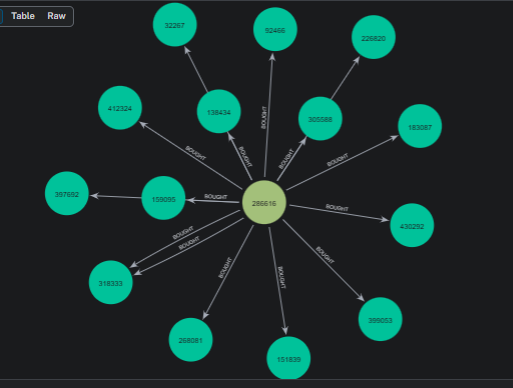

**Interpretasi:**

Graf sebelum penambahan similarity memperlihatkan hubungan antara node Visitor dan Item melalui aktivitas interaksi pengguna terhadap produk. User 286616 digunakan sebagai node acuan yang terhubung dengan sejumlah Item melalui relationship VIEWED dan BOUGHT. Pada visualisasi ini, hubungan SIMILAR_TO tidak ditampilkan sehingga graf hanya memperlihatkan hubungan interaksi antara Visitor dan Item.

### B. Graf Sesudah Perhitungan Similarity

**Query Cypher:**

```cypher

MATCH (u:Visitor {visitorid: 286616})
OPTIONAL MATCH (u)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
WITH u, r, i
LIMIT 15

WITH collect({u:u, r:r, i:i}) AS interaksi

MATCH (u1:Visitor {visitorid: 286616})-[s:SIMILAR_TO]-(u2:Visitor)
WITH interaksi, u1, u2, s
ORDER BY s.similarity DESC
LIMIT 5

UNWIND interaksi AS data
RETURN
    data.u AS Visitor,
    data.r AS Interaksi,
    data.i AS Item,
    u1 AS User_Acuan,
    s AS Similarity,
    u2 AS User_Mirip;
```

**Hasil Visualisasi Graf Sesudah Similarity:**

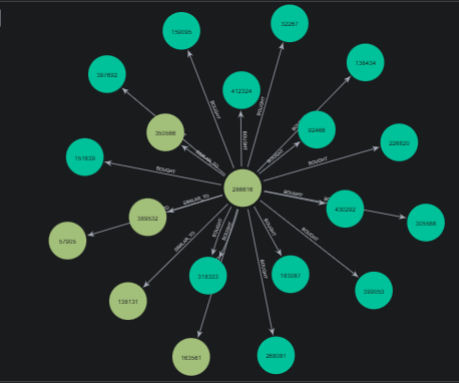

**Interpretasi:**

Graf sesudah perhitungan similarity memperlihatkan penambahan lima relationship SIMILAR_TO yang menghubungkan User 286616 dengan User 163561, 350566, 389532, 57905, dan 138131. Hubungan Visitor–Item tetap dipertahankan, sedangkan relationship SIMILAR_TO menunjukkan tingkat kemiripan pola interaksi antar-User.

### C. Perbandingan Hasil

Sebelum hasil similarity ditampilkan, graf hanya memperlihatkan hubungan interaksi antara Visitor dan Item. Setelah hasil perhitungan similarity ditambahkan, graf memperlihatkan hubungan tambahan antar-Visitor melalui relationship SIMILAR_TO.

User 163561 memiliki nilai Cosine Similarity tertinggi terhadap User 286616 sebesar 0,1463, sedangkan User 138131 memiliki nilai terendah di antara lima User terpilih sebesar 0,1132.

Penambahan relationship SIMILAR_TO memperkaya informasi pada graf sehingga dapat digunakan untuk mengidentifikasi pengguna dengan pola interaksi serupa. Perbandingan dilakukan pada subgraph terpilih, bukan keseluruhan database. Kondisi sebelum similarity direpresentasikan dengan tidak menampilkan relationship SIMILAR_TO.



# 2.2 Analytics

### Nomor 1. Rekomendasi Item Menggunakan KNN

#### 1(a). Pemilihan User Secara Acak dan Penentuan KNN

Pada tahap ini dilakukan pemilihan User secara acak menggunakan random seed 42 agar hasil pemilihan dapat direproduksi. Data RetailRocket periode P1 digunakan sebagai data training, sedangkan periode P2 digunakan sebagai data testing.

Pemilihan User dibatasi pada kandidat yang memiliki minimal lima interaksi pada P1 dan setidaknya satu interaksi pada P2. Selanjutnya, dilakukan pemeriksaan ketersediaan kandidat Item baru dari lima tetangga terdekat agar metode KNN dapat digunakan untuk menghasilkan tiga Item rekomendasi pada Nomor 1(b).

Metode yang digunakan adalah User-Based KNN dengan Cosine Similarity dan nilai k = 5.


In [36]:

# NOMOR 1(a) - PERSIAPAN DATA KNN

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

# Menggunakan data training P1
interaksi = df_p1[
    ["visitorid", "itemid"]
].drop_duplicates()

# Mengambil ID User dan Item unik
user_ids = np.sort(interaksi["visitorid"].unique())
item_ids = np.sort(interaksi["itemid"].unique())

# Mengubah ID menjadi indeks matriks
user_index = pd.Index(user_ids).get_indexer(
    interaksi["visitorid"]
)

item_index = pd.Index(item_ids).get_indexer(
    interaksi["itemid"]
)

# Membentuk matriks sparse User-Item
matriks_user_item = csr_matrix(
    (
        np.ones(len(interaksi), dtype=np.float32),
        (user_index, item_index)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("=== PERSIAPAN DATA KNN ===")
print("Jumlah interaksi unik:", len(interaksi))
print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Ukuran matriks:", matriks_user_item.shape)


=== PERSIAPAN DATA KNN ===
Jumlah interaksi unik: 487584
Jumlah User: 325964
Jumlah Item: 118508
Ukuran matriks: (325964, 118508)


In [37]:

# NOMOR 1(a) - PEMILIHAN USER ACAK
# DENGAN PEMERIKSAAN KELAYAKAN KNN

from sklearn.metrics.pairwise import cosine_similarity

seed = 42
k = 5

# Menghitung jumlah interaksi setiap User
jumlah_p1 = df_p1.groupby("visitorid").size()
jumlah_p2 = df_p2.groupby("visitorid").size()

# Kandidat awal
kandidat_awal = jumlah_p1[
    (jumlah_p1 >= 5) &
    (jumlah_p1.index.isin(jumlah_p2.index))
].index.to_numpy()

kandidat_awal = np.sort(kandidat_awal)

# Mengacak urutan kandidat secara reproducible
rng = np.random.default_rng(seed)
urutan_acak = rng.permutation(kandidat_awal)

user_acak = None
df_tetangga = None
jumlah_item_baru = 0
jumlah_diperiksa = 0

for uid in urutan_acak:

    jumlah_diperiksa += 1

    idx = int(np.searchsorted(user_ids, uid))

    # Cosine Similarity terhadap seluruh User P1
    similarity = cosine_similarity(
        matriks_user_item[idx],
        matriks_user_item
    ).ravel()

    # Mengeluarkan User acuan
    similarity[idx] = -1

    # Hanya tetangga dengan similarity positif
    indeks_valid = np.where(similarity > 0)[0]

    if len(indeks_valid) < k:
        continue

    # Urutkan similarity menurun, lalu ID menaik
    urutan = np.lexsort((
        user_ids[indeks_valid],
        -similarity[indeks_valid]
    ))

    top5 = indeks_valid[urutan[:k]]

    # Item User acuan
    item_acuan = set(
        df_p1.loc[
            df_p1["visitorid"] == uid,
            "itemid"
        ]
    )

    # Item dari lima tetangga
    item_tetangga = set(
        df_p1.loc[
            df_p1["visitorid"].isin(user_ids[top5]),
            "itemid"
        ]
    )

    # Kandidat Item baru
    item_baru = item_tetangga - item_acuan

    if len(item_baru) >= 3:

        user_acak = int(uid)
        jumlah_item_baru = len(item_baru)

        df_tetangga = pd.DataFrame({
            "User Tetangga": user_ids[top5],
            "Cosine Similarity": similarity[top5]
        })

        break

if user_acak is None:
    raise ValueError(
        "Tidak ditemukan User dengan minimal 3 kandidat Item baru."
    )

print("=== HASIL PEMILIHAN USER ACAK ===")
print("Random seed:", seed)
print("Jumlah kandidat awal:", len(kandidat_awal))
print("Jumlah kandidat diperiksa:", jumlah_diperiksa)
print("User terpilih:", user_acak)
print("Jumlah interaksi P1:", jumlah_p1.loc[user_acak])
print("Jumlah interaksi P2:", jumlah_p2.loc[user_acak])
print("Jumlah kandidat Item baru:", jumlah_item_baru)
print("Nilai k:", k)

print("\n=== 5 USER TETANGGA TERDEKAT ===")
display(df_tetangga.round(4))

# Validasi
assert len(df_tetangga) == 5
assert user_acak not in df_tetangga["User Tetangga"].values
assert jumlah_item_baru >= 3

print("\nVALIDASI KNN BERHASIL")


=== HASIL PEMILIHAN USER ACAK ===
Random seed: 42
Jumlah kandidat awal: 538
Jumlah kandidat diperiksa: 4
User terpilih: 783557
Jumlah interaksi P1: 21
Jumlah interaksi P2: 7
Jumlah kandidat Item baru: 13
Nilai k: 5

=== 5 USER TETANGGA TERDEKAT ===


,User Tetangga,Cosine Similarity
0,786332,0.3873
1,1361283,0.3500
2,3030,0.3162
3,120399,0.3162
4,193795,0.3162



VALIDASI KNN BERHASIL



**Interpretasi:**

Hasil pemilihan User menggunakan random seed 42 memperoleh User 783557 setelah memeriksa 4 dari 538 kandidat awal. User tersebut memiliki 21 interaksi pada periode P1 dan 7 interaksi pada periode P2.

Metode User-Based KNN dengan k = 5 dan Cosine Similarity menghasilkan lima User tetangga terdekat, yaitu 786332, 1361283, 3030, 120399, dan 193795. Nilai similarity tertinggi sebesar 0,3873 diperoleh User 786332.

Dari kelima tetangga tersebut, ditemukan 13 kandidat Item baru yang belum pernah diinteraksikan oleh User 783557. Dengan demikian, hasil KNN dapat digunakan untuk menentukan tiga Item rekomendasi pada Nomor 1(b) tanpa menggunakan metode fallback popularitas.

Pemilihan User dilakukan berdasarkan urutan acak dengan seed 42 dan kriteria kelayakan rekomendasi, sehingga hasilnya dapat direproduksi.



#### 1(b). Menentukan 3 Item Rekomendasi dengan KNN


In [38]:

# NOMOR 1(b) - REKOMENDASI 3 ITEM MENGGUNAKAN KNN

# Mengambil 5 User tetangga dari hasil Nomor 1(a)
tetangga = df_tetangga.copy()

# Mengambil Item yang sudah diinteraksikan User acuan
item_user = set(
    df_p1.loc[
        df_p1["visitorid"] == user_acak,
        "itemid"
    ]
)

# Mengambil interaksi Item dari 5 User tetangga
interaksi_tetangga = df_p1.loc[
    df_p1["visitorid"].isin(tetangga["User Tetangga"]),
    ["visitorid", "itemid"]
].drop_duplicates()

# Menggabungkan interaksi dengan skor similarity tetangga
interaksi_tetangga = interaksi_tetangga.merge(
    tetangga,
    left_on="visitorid",
    right_on="User Tetangga",
    how="inner"
)

# Menghapus Item yang sudah pernah diinteraksikan User acuan
kandidat_item = interaksi_tetangga.loc[
    ~interaksi_tetangga["itemid"].isin(item_user)
].copy()

# Menghitung skor setiap Item dari jumlah similarity tetangga
skor_item = (
    kandidat_item.groupby("itemid", as_index=False)
    .agg(
        Skor_KNN=("Cosine Similarity", "sum"),
        Jumlah_Tetangga=("visitorid", "nunique")
    )
)

# Mengurutkan Item berdasarkan skor tertinggi
skor_item = skor_item.sort_values(
    by=["Skor_KNN", "Jumlah_Tetangga", "itemid"],
    ascending=[False, False, True]
).reset_index(drop=True)

# Mengambil 3 rekomendasi terbaik
rekomendasi_3 = skor_item.head(3).copy()

print("=== HASIL REKOMENDASI KNN ===")
print("User acuan:", user_acak)
print("Nilai k:", k)
print("Jumlah kandidat Item baru:", len(skor_item))

print("\n=== 3 ITEM REKOMENDASI TERBAIK ===")
display(rekomendasi_3.round(4))

# Validasi hasil rekomendasi
assert len(rekomendasi_3) == 3
assert not set(rekomendasi_3["itemid"]) & item_user
assert rekomendasi_3["Skor_KNN"].gt(0).all()

print("\nVALIDASI REKOMENDASI BERHASIL")


=== HASIL REKOMENDASI KNN ===
User acuan: 783557
Nilai k: 5
Jumlah kandidat Item baru: 13

=== 3 ITEM REKOMENDASI TERBAIK ===


,itemid,Skor_KNN,Jumlah_Tetangga
0,95467,0.6662,2
1,99604,0.6662,2
2,314642,0.6662,2



VALIDASI REKOMENDASI BERHASIL



**Interpretasi:**

Hasil penerapan User-Based KNN dengan k = 5 pada User 783557 menghasilkan 13 kandidat Item baru yang belum pernah diinteraksikan oleh User tersebut.

Tiga Item dengan skor rekomendasi tertinggi adalah Item 95467, 99604, dan 314642. Ketiganya memiliki skor KNN sebesar 0,6662 dan masing-masing direkomendasikan berdasarkan interaksi dua User tetangga terdekat.

Skor rekomendasi diperoleh dari penjumlahan nilai Cosine Similarity tetangga yang berinteraksi dengan setiap Item. Ketiga Item tersebut dipilih sebagai rekomendasi karena memiliki skor tertinggi di antara kandidat Item yang tersedia.



### Nomor 2. Evaluasi Hasil Rekomendasi KNN

#### 2(a). Perhitungan Hit@5


In [39]:

# NOMOR 2(a) - PERHITUNGAN HIT@5

# Mengambil 5 Item rekomendasi teratas dari KNN
top_5_item = skor_item.head(5)["itemid"].tolist()

# Mengambil Item aktual User pada data testing P2
item_aktual_p2 = set(
    df_p2.loc[
        df_p2["visitorid"] == user_acak,
        "itemid"
    ]
)

# Mencari Item rekomendasi yang cocok dengan data P2
item_cocok = set(top_5_item) & item_aktual_p2

# Hit@5 bernilai 1 jika minimal ada satu Item cocok
# dan bernilai 0 jika tidak ada Item cocok
hit_at_5 = int(len(item_cocok) > 0)

print("=== HASIL EVALUASI HIT@5 ===")
print("User acuan:", user_acak)
print("Nilai k KNN:", k)
print("Top 5 Item rekomendasi:", top_5_item)
print("Item aktual P2:", sorted(item_aktual_p2))
print("Item yang cocok:", sorted(item_cocok))
print("Jumlah Item yang cocok:", len(item_cocok))
print("Nilai Hit@5:", hit_at_5)

# Validasi
assert len(top_5_item) == 5
assert hit_at_5 in [0, 1]

print("\nVALIDASI HIT@5 BERHASIL")


=== HASIL EVALUASI HIT@5 ===
User acuan: 783557
Nilai k KNN: 5
Top 5 Item rekomendasi: [95467, 99604, 314642, 419761, 103621]
Item aktual P2: [88860, 93315, 303493, 318294, 356024, 366239, 458872]
Item yang cocok: []
Jumlah Item yang cocok: 0
Nilai Hit@5: 0

VALIDASI HIT@5 BERHASIL



**Interpretasi:**

Hasil evaluasi Hit@5 pada User 783557 menunjukkan nilai sebesar 0. Dari lima Item rekomendasi KNN, yaitu 95467, 99604, 314642, 419761, dan 103621, tidak ditemukan Item yang sesuai dengan interaksi aktual User pada periode testing P2.

Nilai Hit@5 sebesar 0 menunjukkan bahwa sistem rekomendasi belum berhasil menghasilkan Item relevan pada lima peringkat teratas untuk User yang diuji. Hasil ini tidak menunjukkan kesalahan perhitungan KNN, tetapi menggambarkan bahwa rekomendasi yang dihasilkan belum sesuai dengan interaksi aktual User pada periode testing.



#### 2(b). Perhitungan NDCG@5


In [40]:

# NOMOR 2(b) - PERHITUNGAN NDCG@5

import numpy as np
import pandas as pd

# Mengambil 5 Item rekomendasi dari hasil KNN
top_5_item = skor_item.head(5)["itemid"].tolist()

# Mengambil Item aktual User pada data testing P2
item_aktual_p2 = set(
    df_p2.loc[
        df_p2["visitorid"] == user_acak,
        "itemid"
    ]
)

# Menentukan relevansi setiap Item rekomendasi
# 1 = Item terdapat pada data P2
# 0 = Item tidak terdapat pada data P2
relevansi = [
    int(item in item_aktual_p2)
    for item in top_5_item
]

# Menghitung DCG@5
dcg_at_5 = sum(
    rel / np.log2(peringkat + 1)
    for peringkat, rel in enumerate(relevansi, start=1)
)

# Menghitung IDCG@5 (peringkat ideal)
jumlah_relevan_ideal = min(5, len(item_aktual_p2))

relevansi_ideal = (
    [1] * jumlah_relevan_ideal
    + [0] * (5 - jumlah_relevan_ideal)
)

idcg_at_5 = sum(
    rel / np.log2(peringkat + 1)
    for peringkat, rel in enumerate(relevansi_ideal, start=1)
)

# Menghitung NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0 else 0.0
)

# Menampilkan tabel evaluasi
tabel_ndcg = pd.DataFrame({
    "Peringkat": range(1, 6),
    "Item ID": top_5_item,
    "Relevansi": relevansi,
    "Kontribusi DCG": [
        rel / np.log2(peringkat + 1)
        for peringkat, rel in enumerate(relevansi, start=1)
    ]
})

print("=== HASIL EVALUASI NDCG@5 ===")
print("User acuan:", user_acak)
print("Nilai k KNN:", k)

print("\n=== TABEL RELEVANSI ===")
display(tabel_ndcg.round(4))

print("DCG@5:", round(dcg_at_5, 4))
print("IDCG@5:", round(idcg_at_5, 4))
print("NDCG@5:", round(ndcg_at_5, 4))

# Validasi
assert len(top_5_item) == 5
assert 0 <= ndcg_at_5 <= 1

print("\nVALIDASI NDCG@5 BERHASIL")


=== HASIL EVALUASI NDCG@5 ===
User acuan: 783557
Nilai k KNN: 5

=== TABEL RELEVANSI ===


,Peringkat,Item ID,Relevansi,Kontribusi DCG
0,1,95467,0,0.0
1,2,99604,0,0.0
2,3,314642,0,0.0
3,4,419761,0,0.0
4,5,103621,0,0.0


DCG@5: 0.0
IDCG@5: 2.9485
NDCG@5: 0.0

VALIDASI NDCG@5 BERHASIL



**Interpretasi:**

Hasil evaluasi NDCG@5 pada User 783557 menunjukkan nilai DCG@5 sebesar 0,0000 dan IDCG@5 sebesar 2,9485, sehingga diperoleh NDCG@5 sebesar 0,0000.

Nilai tersebut menunjukkan bahwa tidak terdapat Item relevan pada lima peringkat teratas rekomendasi KNN jika dibandingkan dengan interaksi aktual User pada periode testing P2. Seluruh Item rekomendasi memiliki nilai relevansi 0 sehingga tidak memberikan kontribusi terhadap DCG@5.

Hasil NDCG@5 sebesar 0 menunjukkan bahwa sistem belum berhasil menempatkan Item relevan dalam lima rekomendasi teratas untuk User yang diuji. Hasil ini konsisten dengan evaluasi Hit@5 yang juga memperoleh nilai 0.
